# Experiment: Factor Loading Analysis and Principal Component Variable Identification
**Topic:** Principal Component Analysis & Factor Interpretation  
**Algorithm:** Factor Loading Matrix Decomposition  
**Dataset:** Metropolitan Quality of Life Indicators (Places Rated Almanac Matrix)  
**Objective:** Identify the most influential variables contributing to each principal component (PC1, PC2, PC3), determine the global dominant loading across the entire system, and interpret the semantic meaning of the latent dimensions.

---

## 1. Problem Statement & Mathematical Formulation

In Principal Component Analysis, the relationship between original standardized variables $\mathbf{x} = [x_1, \dots, x_p]^T$ and the principal components $\mathbf{z} = [z_1, \dots, z_k]^T$ is governed by the eigenvector matrix $\mathbf{V} = [\mathbf{v}_1, \dots, \mathbf{v}_k]$:
$$z_j = \sum_{i=1}^{p} v_{ij} x_i$$

### Factor Loadings
The **loading** $l_{ij}$ is the Pearson correlation coefficient between the $i$-th original variable and the $j$-th principal component:
$$l_{ij} = \text{Corr}(x_i, z_j) = v_{ij} \sqrt{\lambda_j}$$
where $\lambda_j$ is the eigenvalue (variance) of the $j$-th principal component.

### Criterion for Variable Importance
1. **Magnitude ($|l_{ij}|$):** The absolute value of the loading indicates the proportion of variance shared between the variable and the component. Variables with higher $|l_{ij}|$ exert stronger influence on that component's orientation in feature space:
   $$i^*_j = \arg\max_{i} |l_{ij}|$$
2. **Sign ($\pm$):** The algebraic sign represents directional correlation. A positive loading implies that higher values of the variable increase the component score; a negative loading implies an inverse relationship.


In [1]:
# Import dependencies
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 120


## 2. Given Component Loading Matrix

The system presents the factor loading matrix for 9 metropolitan livability attributes across the first three principal components:

| Variable | PC1 | PC2 | PC3 |
|:---|:---:|:---:|:---:|
| **Climate** | 0.190 | 0.017 | 0.207 |
| **Housing** | 0.544 | 0.020 | 0.204 |
| **Health** | 0.782 | -0.605 | 0.144 |
| **Crime** | 0.365 | 0.294 | 0.585 |
| **Transportation** | 0.585 | 0.085 | 0.234 |
| **Education** | 0.394 | -0.273 | 0.027 |
| **Arts** | 0.985 | 0.126 | -0.111 |
| **Recreation** | 0.520 | 0.402 | 0.519 |
| **Economy** | 0.142 | 0.150 | 0.239 |


In [2]:
# Construct DataFrame of factor loadings
loadings = pd.DataFrame({
    "Variable": [
        "Climate", "Housing", "Health", "Crime",
        "Transportation", "Education", "Arts",
        "Recreation", "Economy"
    ],
    "PC1": [0.190, 0.544, 0.782, 0.365, 0.585, 0.394, 0.985, 0.520, 0.142],
    "PC2": [0.017, 0.020, -0.605, 0.294, 0.085, -0.273, 0.126, 0.402, 0.150],
    "PC3": [0.207, 0.204, 0.144, 0.585, 0.234, 0.027, -0.111, 0.519, 0.239]
})

print("Principal Component Loadings Table:")
display(loadings)


Principal Component Loadings Table:


,Variable,PC1,PC2,PC3
0,Climate,0.190,0.017,0.207
1,Housing,0.544,0.020,0.204
2,Health,0.782,-0.605,0.144
3,Crime,0.365,0.294,0.585
4,Transportation,0.585,0.085,0.234
5,Education,0.394,-0.273,0.027
6,Arts,0.985,0.126,-0.111
7,Recreation,0.520,0.402,0.519
8,Economy,0.142,0.150,0.239


## 3. Visualization: Factor Loading Heatmap

Visualizing the loading matrix highlights dominant variable associations and cross-component contrasts.


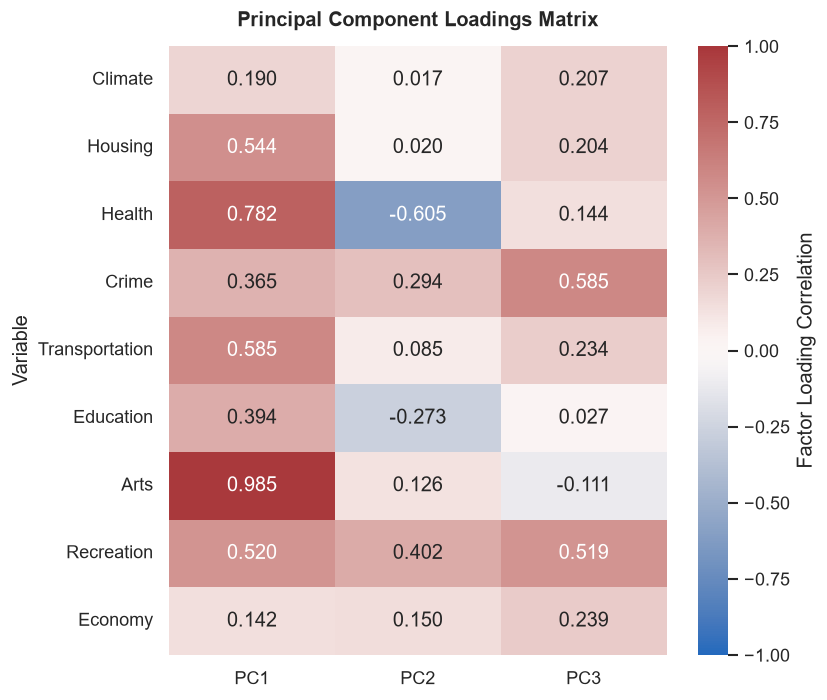

In [3]:
plt.figure(figsize=(7, 6))
heatmap_df = loadings.set_index("Variable")[["PC1", "PC2", "PC3"]]

sns.heatmap(
    heatmap_df,
    annot=True,
    fmt=".3f",
    cmap="vlag",
    center=0,
    vmin=-1.0,
    vmax=1.0,
    cbar_kws={'label': 'Factor Loading Correlation'}
)
plt.title("Principal Component Loadings Matrix", fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


## 4. Identifying the Dominant Variable per Principal Component

For each component $k \in \{\text{PC1}, \text{PC2}, \text{PC3}\}$, we locate the variable that exhibits the largest absolute loading:
$$v_k^* = \arg\max_{v} |\text{Loading}(v, k)|$$


In [4]:
results_per_pc = []

for pc in ["PC1", "PC2", "PC3"]:
    idx = loadings[pc].abs().idxmax()
    var_name = loadings.loc[idx, "Variable"]
    raw_val = loadings.loc[idx, pc]
    abs_val = abs(raw_val)
    results_per_pc.append({
        "Component": pc,
        "Strongest Variable": var_name,
        "Raw Loading": raw_val,
        "Absolute Loading": abs_val,
        "Direction": "Positive Correlation" if raw_val > 0 else "Inverse Correlation"
    })

results_df = pd.DataFrame(results_per_pc)
print("Strongest Contributing Variable per Principal Component:")
display(results_df)


Strongest Contributing Variable per Principal Component:


,Component,Strongest Variable,Raw Loading,Absolute Loading,Direction
0,PC1,Arts,0.985,0.985,Positive Correlation
1,PC2,Health,-0.605,0.605,Inverse Correlation
2,PC3,Crime,0.585,0.585,Positive Correlation


### Visualizing Variable Contributions per Component
We display the relative loading magnitudes for PC1, PC2, and PC3 sorted by impact.


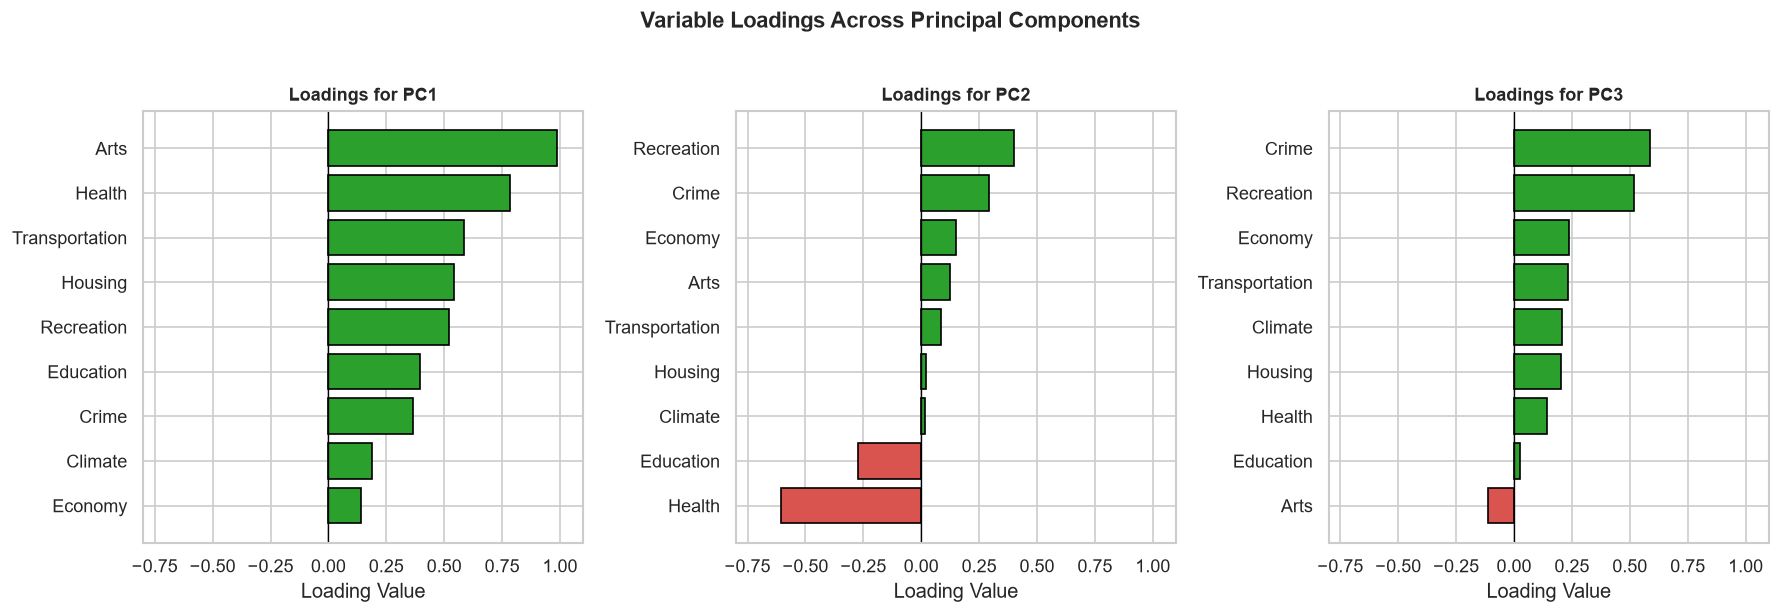

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, pc in enumerate(["PC1", "PC2", "PC3"]):
    sorted_df = loadings.sort_values(by=pc, ascending=True)
    colors = ['#2ca02c' if v > 0 else '#d9534f' for v in sorted_df[pc]]
    axes[i].barh(sorted_df["Variable"], sorted_df[pc], color=colors, edgecolor='black')
    axes[i].axvline(0, color='black', linewidth=0.8)
    axes[i].set_xlim(-0.8, 1.1)
    axes[i].set_title(f"Loadings for {pc}", fontsize=11, fontweight='bold')
    axes[i].set_xlabel("Loading Value")

plt.suptitle("Variable Loadings Across Principal Components", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 5. Identifying the Global Maximum Loading in the Entire Table

We reshape the loading matrix into long format to find the single highest absolute loading in the entire table.


In [6]:
long_loadings = loadings.melt(
    id_vars="Variable",
    var_name="Principal_Component",
    value_name="Loading"
)
long_loadings["Absolute_Loading"] = long_loadings["Loading"].abs()

# Sort by absolute loading in descending order
ranked_loadings = long_loadings.sort_values(by="Absolute_Loading", ascending=False).reset_index(drop=True)

print("Top 5 Loadings Across Entire System:")
display(ranked_loadings.head(5))

strongest = ranked_loadings.iloc[0]
print("\n=======================================================")
print(f"GLOBAL STRONGEST LOADING IN ENTIRE TABLE:")
print(f"  Variable:            {strongest['Variable']}")
print(f"  Principal Component: {strongest['Principal_Component']}")
print(f"  Loading Value:       {strongest['Loading']:.3f} (|loading| = {strongest['Absolute_Loading']:.3f})")
print("=======================================================")


Top 5 Loadings Across Entire System:


,Variable,Principal_Component,Loading,Absolute_Loading
0,Arts,PC1,0.985,0.985
1,Health,PC1,0.782,0.782
2,Health,PC2,-0.605,0.605
3,Crime,PC3,0.585,0.585
4,Transportation,PC1,0.585,0.585



GLOBAL STRONGEST LOADING IN ENTIRE TABLE:
  Variable:            Arts
  Principal Component: PC1
  Loading Value:       0.985 (|loading| = 0.985)


## 6. Semantic Factor Interpretation

1. **PC1 — Cultural & Metropolitan Vibrancy:**
   - Dominated overwhelmingly by **Arts (loading = +0.985)**, followed by **Health (+0.782)**, **Transportation (+0.585)**, and **Housing (+0.544)**.
   - All loadings on PC1 are positive, indicating that PC1 represents an aggregate measure of urban infrastructure and cultural activity.
2. **PC2 — Health & Education vs. Outdoor Leisure Divergence:**
   - Dominated by **Health (loading = -0.605)** and **Education (-0.273)** in the negative direction versus **Recreation (+0.402)** in the positive direction.
   - Represents a trade-off dimension separating metropolitan centers with extensive institutional healthcare from recreational/leisure-driven regions.
3. **PC3 — Urban Density & Public Safety Index:**
   - Dominated by **Crime (loading = +0.585)** and **Recreation (+0.519)**.
   - Captures social friction and urban density pressures.


## 7. Final Answers & Conclusion

### Summary of Question Answers
- **Strongest variable for PC1:** **Arts** (loading = **+0.985**)
- **Strongest variable for PC2:** **Health** (loading = **-0.605**, absolute magnitude = **0.605**)
- **Strongest variable for PC3:** **Crime** (loading = **+0.585**)

### Single Strongest Variable in the Entire Table:
$$\mathbf{\text{Arts on PC1}} \quad (\text{Loading} = \mathbf{0.985})$$

With an absolute correlation of $0.985$, the Arts indicator accounts for over $97\%$ ($0.985^2 \approx 0.970$) of its individual variance aligned with the first principal component.
